# 04 — Equidade do modelo publicado, por faixa etária

> Audita o modelo que está em produção — o `models/model.joblib` que `make train` publica e a
> API serve —, com a regra de decisão que ele usa (recusa a partir de 0,5), na partição de
> **teste** e nas quatro faixas etárias do pacote (`credito.model.evaluate.FAIXAS_ETARIAS`).
> O modelo não é alterado: tudo aqui é medição.
>
> Para reexecutar: `make train` (para existir o modelo publicado), `poetry install --with
> notebooks` e depois `make equidade`.

A auditoria responde a quatro perguntas, em ordem:

1. **As diferenças entre faixas são maiores que o acaso?** (incerteza amostral)
2. **Comparando pessoas que terminaram do mesmo jeito, o modelo as trata igual?** (análise
   condicional ao desfecho e ao score)
3. **A idade, sozinha, muda a decisão do modelo?** (contrafactual)
4. **Dá para igualar as faixas, e a que custo?** (o limite entre critérios de equidade)

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from credito.config import get_settings
from credito.data.arff import ler_arff
from credito.data.prepare import limpar, separar
from credito.model.evaluate import (
    FAIXAS_ETARIAS,
    avaliar_por_faixa_etaria,
    diferenca_de_oportunidade,
    razao_impacto_adverso,
)
from credito.model.train import carregar_modelo
from credito.schema import ALVO, FEATURES

warnings.filterwarnings("ignore", category=UserWarning)
pd.options.display.float_format = "{:,.4f}".format

# Uma cor por faixa, na mesma ordem em todos os gráficos (paleta categórica validada).
CORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
TINTA, TINTA_2, GRADE, FUNDO = "#0b0b0b", "#52514e", "#e5e4df", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "figure.facecolor": FUNDO,
        "axes.facecolor": FUNDO,
        "axes.edgecolor": TINTA_2,
        "axes.labelcolor": TINTA_2,
        "axes.titlecolor": TINTA,
        "axes.titlesize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRADE,
        "grid.linewidth": 0.8,
        "xtick.color": TINTA_2,
        "ytick.color": TINTA_2,
        "font.size": 10,
        "legend.frameon": False,
    }
)

settings = get_settings()
SEMENTE = settings.random_seed
X = list(FEATURES)
LIMIAR = 0.5
FAIXAS = list(FAIXAS_ETARIAS)
COR = dict(zip(FAIXAS, CORES, strict=True))

referencia, _ = limpar(ler_arff(settings.dataset_path))
particoes = separar(
    referencia,
    test_size=settings.test_size,
    validation_size=settings.validation_size,
    seed=SEMENTE,
)
validacao, teste = particoes["validacao"], particoes["teste"]

modelo, metadados = carregar_modelo(settings.model_path)
print(f"modelo publicado: {metadados.get('candidato')} | teste: {len(teste):,} pedidos")


def faixa_de(frame: pd.DataFrame) -> np.ndarray:
    indice = np.full(len(frame), -1)
    for i, (minimo, maximo) in enumerate(FAIXAS_ETARIAS.values()):
        indice[frame["age"].between(minimo, maximo).to_numpy()] = i
    return indice


y = teste[ALVO].to_numpy()
p = modelo.predict_proba(teste[X])[:, 1]
recusa = p >= LIMIAR
faixa = faixa_de(teste)
assert (faixa >= 0).all()

modelo publicado: xgboost | teste: 23,584 pedidos


## 1. O ponto de partida: os números da governança

Antes de ir além, a seção confere que o modelo e o recorte reproduzem a medição que o projeto
já publica — com as funções do próprio pacote.

In [2]:
por_faixa = avaliar_por_faixa_etaria(modelo, teste, limiar=LIMIAR)
quatro_quintos = razao_impacto_adverso(por_faixa)
oportunidade = diferenca_de_oportunidade(por_faixa)
partida = pd.DataFrame(
    {
        nome: {
            "n": f["n"],
            "inadimplência real": f["taxa_de_positivos_real"],
            "aprovação": f["taxa_de_aprovacao"],
            "razão 4/5": quatro_quintos["faixas"][nome]["razao"],
            "recall": f.get("recall_positivo", np.nan),
        }
        for nome, f in por_faixa.items()
    }
).T
display(partida)
print(
    f"faixa de referência dos 4/5: {quatro_quintos['referencia']} | "
    f"referência do recall: {oportunidade['referencia']}"
)

,n,inadimplência real,aprovação,razão 4/5,recall
18-25,486.0000,0.0864,0.6502,0.7030,0.7857
26-40,"5,399.0000",0.1058,0.6809,0.7361,0.7671
41-60,"11,302.0000",0.0724,0.7838,0.8473,0.6822
61+,"6,397.0000",0.0322,0.9250,1.0000,0.5000


faixa de referência dos 4/5: 61+ | referência do recall: 18-25


O quadro é o mesmo que a governança descreve: as faixas 18-25 e 26-40 ficam abaixo de 0,80 na
razão 4/5, e a faixa 61+ tem o menor recall — o modelo deixa passar cerca de metade dos
inadimplentes idosos.

Os valores coincidem com os publicados na governança.

## 2. As diferenças são maiores que o acaso?

Bootstrap com 2.000 reamostras do teste. Em cada uma, todas as métricas são recalculadas por
faixa. Além de aprovação, razão 4/5 e recall, entra uma métrica que o projeto ainda não mede:
a **taxa de bons pagadores recusados** (taxa de falso positivo) — entre quem pagaria em dia,
quantos o modelo recusa.

In [3]:
REFERENCIA = FAIXAS.index("61+")


def metricas(indice: np.ndarray) -> dict[str, np.ndarray]:
    f, yy, rr = faixa[indice], y[indice], recusa[indice]
    n = np.bincount(f, minlength=4)
    positivos = np.bincount(f, weights=yy, minlength=4)
    aprovados = np.bincount(f, weights=~rr, minlength=4)
    vp = np.bincount(f, weights=rr & (yy == 1), minlength=4)
    fp = np.bincount(f, weights=rr & (yy == 0), minlength=4)
    aprovacao = aprovados / n
    return {
        "aprovação": aprovacao,
        "razão 4/5": aprovacao / aprovacao[REFERENCIA],
        "recall": vp / positivos,
        "bons pagadores recusados": fp / (n - positivos),
    }


pontual = metricas(np.arange(len(y)))
gerador = np.random.default_rng(SEMENTE)
amostras = {nome: [] for nome in pontual}
for _ in range(2000):
    m = metricas(gerador.integers(len(y), size=len(y)))
    for nome, valor in m.items():
        amostras[nome].append(valor)
amostras = {nome: np.array(v) for nome, v in amostras.items()}

linhas = []
for nome in pontual:
    baixo, alto = np.quantile(amostras[nome], [0.025, 0.975], axis=0)
    for i, f in enumerate(FAIXAS):
        linhas.append(
            {
                "métrica": nome,
                "faixa": f,
                "valor": pontual[nome][i],
                "IC95 inferior": baixo[i],
                "IC95 superior": alto[i],
            }
        )
incerteza = pd.DataFrame(linhas).set_index(["métrica", "faixa"])
display(incerteza)

valor  IC95 inferior  IC95 superior
métrica                  faixa                                     
aprovação                18-25 0.6502         0.6055         0.6943
                         26-40 0.6809         0.6687         0.6934
                         41-60 0.7838         0.7766         0.7911
                         61+   0.9250         0.9189         0.9311
razão 4/5                18-25 0.7030         0.6543         0.7514
                         26-40 0.7361         0.7227         0.7498
                         41-60 0.8473         0.8376         0.8566
                         61+   1.0000         1.0000         1.0000
recall                   18-25 0.7857         0.6486         0.9048
                         26-40 0.7671         0.7324         0.8022
                         41-60 0.6822         0.6514         0.7127
                         61+   0.5000         0.4313         0.5687
bons pagadores recusados 18-25 0.3086         0.2665         0.3517
                         26-40 0.2662         0.2538         0.2785
                         41-60 0.1799         0.1724         0.1871
                         61+   0.0609         0.0551         0.0666

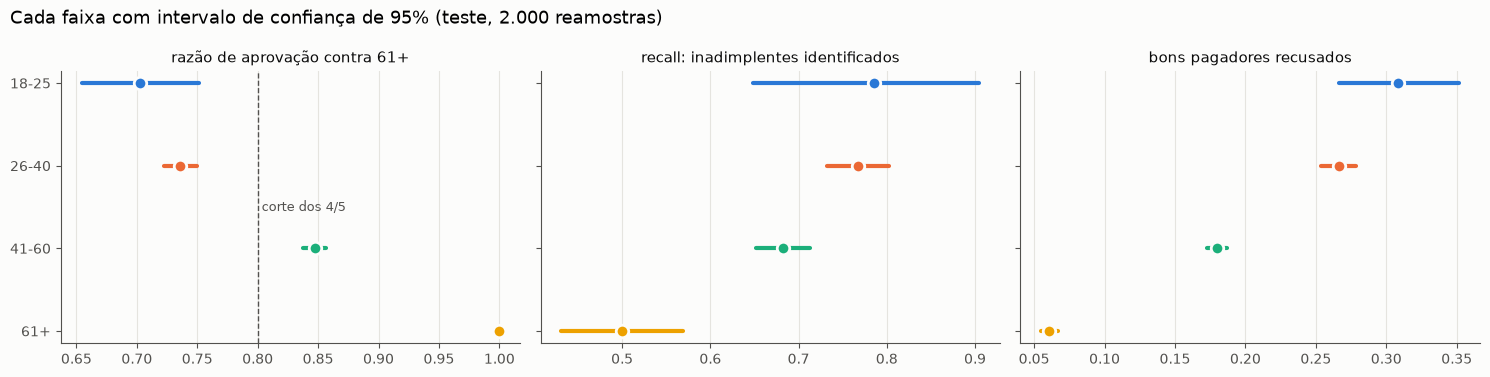

In [4]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
PAINEIS = [
    ("razão 4/5", "razão de aprovação contra 61+", 0.8, "corte dos 4/5"),
    ("recall", "recall: inadimplentes identificados", None, None),
    ("bons pagadores recusados", "bons pagadores recusados", None, None),
]
y_pos = np.arange(len(FAIXAS))[::-1]
for ax, (metrica, titulo, linha, rotulo) in zip(eixos, PAINEIS, strict=True):
    tabela = incerteza.loc[metrica]
    for i, f in enumerate(FAIXAS):
        ax.plot(
            [tabela.loc[f, "IC95 inferior"], tabela.loc[f, "IC95 superior"]],
            [y_pos[i]] * 2,
            color=COR[f],
            linewidth=3,
            solid_capstyle="round",
        )
        ax.plot(
            tabela.loc[f, "valor"],
            y_pos[i],
            "o",
            color=COR[f],
            markersize=9,
            markeredgecolor=FUNDO,
            markeredgewidth=2,
        )
    if linha is not None:
        ax.axvline(linha, color=TINTA_2, linestyle="--", linewidth=1)
        ax.text(linha, 1.5, f" {rotulo}", color=TINTA_2, fontsize=9, va="center")
    ax.set_title(titulo)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
eixos[0].set_yticks(y_pos, FAIXAS)
fig.suptitle(
    "Cada faixa com intervalo de confiança de 95% (teste, 2.000 reamostras)",
    x=0.01,
    ha="left",
    fontsize=13,
)
fig.tight_layout()
plt.show()

In [5]:
def diferenca(metrica: str, a: str, b: str) -> str:
    d = amostras[metrica][:, FAIXAS.index(a)] - amostras[metrica][:, FAIXAS.index(b)]
    valor = pontual[metrica][FAIXAS.index(a)] - pontual[metrica][FAIXAS.index(b)]
    baixo, alto = np.quantile(d, [0.025, 0.975])
    return f"{valor:+.4f} [{baixo:+.4f}, {alto:+.4f}]" + ("" if baixo <= 0 <= alto else "  *")


razao = amostras["razão 4/5"]
contrastes = pd.DataFrame(
    {
        "diferença [IC95]": {
            "recall: 61+ menos 18-25": diferenca("recall", "61+", "18-25"),
            "recall: 61+ menos 41-60": diferenca("recall", "61+", "41-60"),
            "bons recusados: 18-25 menos 61+": diferenca(
                "bons pagadores recusados", "18-25", "61+"
            ),
            "bons recusados: 26-40 menos 41-60": diferenca(
                "bons pagadores recusados", "26-40", "41-60"
            ),
        }
    }
)
display(contrastes)
for f in ("18-25", "26-40"):
    abaixo = (razao[:, FAIXAS.index(f)] < 0.8).mean()
    print(f"{f}: razão 4/5 abaixo de 0,80 em {abaixo:.1%} das reamostras")
print("* = intervalo não cruza o zero")

,diferença [IC95]
recall: 61+ menos 18-25,"-0.2857 [-0.4211, -0.1332] *"
recall: 61+ menos 41-60,"-0.1822 [-0.2578, -0.1058] *"
bons recusados: 18-25 menos 61+,"+0.2477 [+0.2050, +0.2919] *"
bons recusados: 26-40 menos 41-60,"+0.0863 [+0.0721, +0.1005] *"


18-25: razão 4/5 abaixo de 0,80 em 100.0% das reamostras
26-40: razão 4/5 abaixo de 0,80 em 100.0% das reamostras
* = intervalo não cruza o zero


**A razão 4/5 não é acaso.** As faixas 18-25 e 26-40 ficam abaixo de 0,80 em **100% das 2.000
reamostras**. Mesmo a 18-25, com só 486 pessoas, tem intervalo de 0,65 a 0,75, inteiro abaixo
do corte.

**O recall baixo dos idosos também não é acaso.** O recall da faixa 61+ é 0,29 menor que o da
18-25 (intervalo de −0,42 a −0,13) e 0,18 menor que o da 41-60 (−0,26 a −0,11). O intervalo da
18-25 é largo (0,65 a 0,90), como esperado com cerca de 42 inadimplentes, mas não chega a
encostar no da 61+.

**A métrica nova é a mais forte de todas.** Entre os **bons pagadores** — pessoas que pagariam
em dia —, o modelo recusa:

| Faixa | Bons pagadores recusados |
|---|---:|
| 18-25 | **30,9%** (IC de 26,7% a 35,2%) |
| 26-40 | 26,6% |
| 41-60 | 18,0% |
| 61+ | **6,1%** (IC de 5,5% a 6,7%) |

Um jovem que pagaria em dia tem **5,1 vezes** mais chance de ser recusado que um idoso que
pagaria em dia. Essa diferença não se explica por risco: todas essas pessoas são, por
definição, bons pagadores.

## 3. Comparando quem terminou do mesmo jeito

A razão 4/5 compara aprovação crua, e a inadimplência real difere muito entre as faixas (de
cerca de 3% a 11%). Comparações que descontam isso:

- **Entre os bons pagadores:** a taxa de recusados da seção 2. Se jovens que pagariam em dia
  são recusados mais que idosos que pagariam em dia, a diferença não se explica pelo risco.
- **Entre os inadimplentes:** o recall, também na seção 2.
- **Para o mesmo score:** se o modelo é justo nesse sentido, pessoas com o mesmo score têm a
  mesma inadimplência real, qualquer que seja a idade. É a **calibração por grupo**.

O modelo publicado foi treinado com peso de classe, que infla as probabilidades
(`03_baseline.ipynb`, seção 4). Para ler o score como probabilidade, aplica-se a correção de
prior $p' = p / (p + w(1-p))$, com o peso $w$ do próprio modelo. Ela não muda a ordem nem as
decisões.

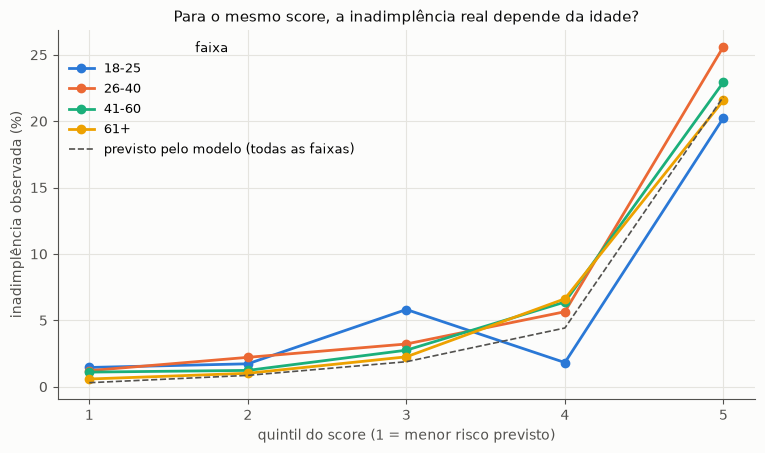

,previsto,observado,previsto / observado
faixa,,,
18-25,0.0834,0.0864,0.9647
26-40,0.0886,0.1058,0.8374
41-60,0.0620,0.0724,0.8569
61+,0.0254,0.0322,0.7883


faixa,18-25,26-40,41-60,61+
quintil,,,,
0,69,331,1728,2589
1,58,814,2361,1484
2,86,1119,2400,1111
3,110,1452,2415,740
4,163,1683,2398,473


In [6]:
peso = modelo[-1].get_params()["scale_pos_weight"]
p_corrigida = p / (p + peso * (1 - p))
quintil = pd.qcut(p_corrigida, 5, labels=False)
tabela = pd.DataFrame(
    {"faixa": np.array(FAIXAS)[faixa], "quintil": quintil, "y": y, "p": p_corrigida}
)

por_quintil = tabela.groupby(["quintil", "faixa"]).agg(
    n=("y", "size"), previsto=("p", "mean"), observado=("y", "mean")
)
fig, ax = plt.subplots(figsize=(9, 4.8))
for f in FAIXAS:
    parte = por_quintil.xs(f, level="faixa")
    ax.plot(
        parte.index + 1,
        parte["observado"] * 100,
        color=COR[f],
        linewidth=2,
        marker="o",
        markersize=6,
        label=f,
    )
geral = tabela.groupby("quintil")["p"].mean() * 100
ax.plot(
    geral.index + 1,
    geral.values,
    color=TINTA_2,
    linestyle="--",
    linewidth=1.2,
    label="previsto pelo modelo (todas as faixas)",
)
ax.set_xticks(range(1, 6))
ax.set(
    xlabel="quintil do score (1 = menor risco previsto)",
    ylabel="inadimplência observada (%)",
    title="Para o mesmo score, a inadimplência real depende da idade?",
)
ax.legend(title="faixa", fontsize=9, title_fontsize=9)
plt.show()

calibracao = (
    tabela.groupby("faixa").agg(previsto=("p", "mean"), observado=("y", "mean")).loc[FAIXAS]
)
calibracao["previsto / observado"] = calibracao["previsto"] / calibracao["observado"]
display(calibracao)
display(por_quintil.unstack("faixa")["n"])

**Para o mesmo score, a inadimplência real é parecida em todas as faixas.** As linhas de 26-40,
41-60 e 61+ quase se sobrepõem em todos os quintis. A de 18-25 oscila, mas com 58 a 163
pessoas por quintil essa oscilação é do tamanho do ruído. Na média por faixa, o modelo
corrigido prevê entre 79% e 96% da inadimplência observada: subestima um pouco todas as
faixas, sem favorecer nenhuma de forma clara.

Ou seja: **o modelo é aproximadamente justo no sentido da calibração** — um score significa o
mesmo risco qualquer que seja a idade. E é justamente isso que explica as diferenças da seção
2. Como os jovens inadimplem mais, mais deles têm score alto; com o mesmo corte para todos,
mais jovens são recusados — inclusive mais jovens que pagariam em dia. Calibração igual e taxas
de erro iguais não cabem juntas quando o risco real difere entre os grupos. A seção 5 mede
esse limite.

## 4. A idade, sozinha, muda a decisão?

O modelo publicado recebe a idade como variável. O teste contrafactual troca **só a idade** de
cada pessoa do teste pela mediana de outra faixa — mantendo renda, uso de crédito e histórico
exatamente iguais — e mede quantas decisões mudam.

Isso mede **o que o modelo faz com a idade**, não o que a idade faz com o risco de uma pessoa
real: alguém de 25 anos que chegasse aos 50 teria outro histórico. Essa segunda pergunta é a da
análise causal (`02_analise_causal.ipynb`, parte 1).

In [7]:
medianas = {f: int(teste.loc[faixa == i, "age"].median()) for i, f in enumerate(FAIXAS)}
print("idade usada para cada faixa:", medianas)

aprovados_viram_recusa, recusados_viram_aprovacao = {}, {}
for i, origem in enumerate(FAIXAS):
    grupo = teste[faixa == i]
    recusa_original = recusa[faixa == i]
    aprovados_viram_recusa[origem], recusados_viram_aprovacao[origem] = {}, {}
    for idade in medianas.values():
        nova = modelo.predict_proba(grupo[X].assign(age=idade))[:, 1] >= LIMIAR
        recusados_viram_aprovacao[origem][f"com {idade} anos"] = (~nova[recusa_original]).mean()
        aprovados_viram_recusa[origem][f"com {idade} anos"] = nova[~recusa_original].mean()

print("\nentre os RECUSADOS de cada faixa, fração que seria APROVADA com outra idade:")
display(pd.DataFrame(recusados_viram_aprovacao).T)
print("entre os APROVADOS de cada faixa, fração que seria RECUSADA com outra idade:")
display(pd.DataFrame(aprovados_viram_recusa).T)

idade usada para cada faixa: {'18-25': 24, '26-40': 34, '41-60': 50, '61+': 68}



entre os RECUSADOS de cada faixa, fração que seria APROVADA com outra idade:


,com 24 anos,com 34 anos,com 50 anos,com 68 anos
18-25,0.0294,0.1882,0.1294,0.5471
26-40,0.0476,0.0743,0.0998,0.4794
41-60,0.0548,0.0712,0.0409,0.4640
61+,0.0354,0.0792,0.0271,0.2500


entre os APROVADOS de cada faixa, fração que seria RECUSADA com outra idade:


,com 24 anos,com 34 anos,com 50 anos,com 68 anos
18-25,0.0411,0.0696,0.1203,0.0032
26-40,0.2035,0.0174,0.0354,0.0024
41-60,0.2217,0.0627,0.0246,0.0009
61+,0.1888,0.0739,0.0651,0.0042


**O modelo dá um peso grande à idade avançada, em si.** Com renda, crédito e histórico
idênticos:

- **55%** dos jovens de 18-25 recusados seriam **aprovados** se tivessem 68 anos. Com 50 anos,
  só 13%.
- **46%** dos recusados de 41-60 seriam aprovados com 68 anos.
- **22,2%** dos aprovados de 41-60 seriam **recusados** com 24 anos.

O efeito não é linear: entre 24 e 50 anos a idade muda poucas decisões (de 3% a 19% dos
recusados), mas chegar à faixa 61+ muda metade delas. O modelo aprendeu que ter mais de 60 anos
é, sozinho, um forte sinal de baixo risco.

Isso conversa com a análise causal: no **risco real**, a parte da diferença entre idades que
não passa pelo comportamento de crédito era de 20% a 26% (`02_analise_causal.ipynb`, seção 3).
Aqui, na **decisão do modelo**, a idade isolada vira a decisão de metade das pessoas. O modelo
pode estar usando a idade com mais força do que o risco direto justifica — e, se isso for
verdade, parte da recusa dos jovens bons pagadores vem da idade, não do comportamento.

## 5. Dá para igualar as faixas, e a que custo?

Quando a inadimplência real difere entre grupos, **nenhum modelo consegue igualar ao mesmo
tempo** aprovação, taxa de bons pagadores recusados, recall e calibração entre eles — é um
resultado matemático, não uma limitação deste modelo. Toda política de equidade escolhe o que
igualar e aceita o que fica desigual.

Para tornar a escolha concreta, três políticas com **um limiar por faixa**, cada uma igualando
uma coisa diferente. Os limiares são escolhidos na **validação** e medidos no **teste**. As três
mantêm a mesma regra de decisão do modelo; só mudam o ponto de corte por faixa.

Uma ressalva que vale para as três: limiar por faixa etária é tratamento diferenciado
declarado por idade. Esta seção mede o que cada política faria, não recomenda adotá-la.

In [8]:
p_val = modelo.predict_proba(validacao[X])[:, 1]
y_val = validacao[ALVO].to_numpy()
faixa_val = faixa_de(validacao)
recusa_val = p_val >= LIMIAR
alvo_recall = recusa_val[y_val == 1].mean()
alvo_fp = recusa_val[y_val == 0].mean()
alvo_aprovacao = 1 - recusa_val.mean()


def limiares(politica: str) -> np.ndarray:
    saida = np.empty(4)
    for i in range(4):
        pp, yy = p_val[faixa_val == i], y_val[faixa_val == i]
        if politica == "igualar recall":
            saida[i] = np.quantile(pp[yy == 1], 1 - alvo_recall)
        elif politica == "igualar bons pagadores recusados":
            saida[i] = np.quantile(pp[yy == 0], 1 - alvo_fp)
        else:
            saida[i] = np.quantile(pp, alvo_aprovacao)
    return saida


def medir_politica(corte: np.ndarray) -> pd.DataFrame:
    rr = p >= corte[faixa]
    linhas = {}
    for i, f in enumerate(FAIXAS):
        m = faixa == i
        linhas[f] = {
            "limiar": corte[i],
            "aprovação": 1 - rr[m].mean(),
            "recall": rr[m & (y == 1)].mean(),
            "bons pagadores recusados": rr[m & (y == 0)].mean(),
            "inadimplência entre aprovados": y[m & ~rr].mean(),
        }
    linhas["total"] = {
        "limiar": np.nan,
        "aprovação": 1 - rr.mean(),
        "recall": rr[y == 1].mean(),
        "bons pagadores recusados": rr[y == 0].mean(),
        "inadimplência entre aprovados": y[~rr].mean(),
    }
    return pd.DataFrame(linhas).T


politicas = {"atual (0,5 para todos)": np.full(4, LIMIAR)}
for nome in ("igualar recall", "igualar bons pagadores recusados", "igualar aprovação"):
    politicas[nome] = limiares(nome)
resultado_politicas = pd.concat({nome: medir_politica(c) for nome, c in politicas.items()})
display(resultado_politicas)

limiar  aprovação  recall  \
atual (0,5 para todos)           18-25  0.5000     0.6502  0.7857   
                                 26-40  0.5000     0.6809  0.7671   
                                 41-60  0.5000     0.7838  0.6822   
                                 61+    0.5000     0.9250  0.5000   
                                 total     NaN     0.7958  0.6915   
igualar recall                   18-25  0.5646     0.7284  0.7619   
                                 26-40  0.6104     0.7751  0.6848   
                                 41-60  0.4978     0.7821  0.6846   
                                 61+    0.2880     0.8218  0.7184   
                                 total     NaN     0.7902  0.6909   
igualar bons pagadores recusados 18-25  0.6669     0.8086  0.6190   
                                 26-40  0.6194     0.7803  0.6760   
                                 41-60  0.5161     0.7949  0.6589   
                                 61+    0.2776     0.8151  0.7233   
                                 total     NaN     0.7973  0.6720   
igualar aprovação                18-25  0.6668     0.8086  0.6190   
                                 26-40  0.6397     0.7913  0.6620   
                                 41-60  0.5187     0.7967  0.6589   
                                 61+    0.2558     0.7943  0.7573   
                                 total     NaN     0.7950  0.6714   

                                        bons pagadores recusados  \
atual (0,5 para todos)           18-25                    0.3086   
                                 26-40                    0.2662   
                                 41-60                    0.1799   
                                 61+                      0.0609   
                                 total                    0.1679   
igualar recall                   18-25                    0.2252   
                                 26-40                    0.1705   
                                 41-60                    0.1815   
                                 61+                      0.1602   
                                 total                    0.1740   
igualar bons pagadores recusados 18-25                    0.1509   
                                 26-40                    0.1657   
                                 41-60                    0.1697   
                                 61+                      0.1670   
                                 total                    0.1677   
igualar aprovação                18-25                    0.1509   
                                 26-40                    0.1551   
                                 41-60                    0.1678   
                                 61+                      0.1874   
                                 total                    0.1702   

                                        inadimplência entre aprovados  
atual (0,5 para todos)           18-25                         0.0285  
                                 26-40                         0.0362  
                                 41-60                         0.0294  
                                 61+                           0.0174  
                                 total                         0.0269  
igualar recall                   18-25                         0.0282  
                                 26-40                         0.0430  
                                 41-60                         0.0292  
                                 61+                           0.0110  
                                 total                         0.0272  
igualar bons pagadores recusados 18-25                         0.0407  
                                 26-40                         0.0439  
                                 41-60                         0.0311  
                                 61+                           0.0109  
                                 total                         0.0286  
igualar a

| Política | O que fica igual entre as faixas | O que fica desigual | Recall total | Aprovação total |
|---|---|---|---:|---:|
| atual | o limiar | tudo: bons recusados de 6% a 31%, recall de 0,50 a 0,79 | 0,692 | 79,6% |
| igualar recall | recall (0,68 a 0,76) | bons recusados de 16% a 23%; aprovação de 73% a 82% | 0,691 | 79,0% |
| igualar bons recusados | bons recusados (15% a 17%) | recall de 0,62 a 0,72 | 0,672 | 79,7% |
| igualar aprovação | aprovação (79% a 81%) | recall de 0,62 a 0,76 | 0,671 | 79,5% |

Três leituras:

1. **Todas as políticas reduzem muito a desigualdade atual**, que é a maior de todas: hoje o
   modelo é mais severo com os jovens em *tudo* — recusa mais bons pagadores e pega mais
   inadimplentes.
2. **Igualar bons pagadores recusados e igualar aprovação quase coincidem aqui.** As duas
   levam a razão 4/5 de todas as faixas para perto de 1 e custam cerca de 2 pontos de recall
   total (0,692 para 0,672), com aprovação total praticamente igual.
3. **Nenhuma iguala tudo.** Em todas, a inadimplência entre os aprovados continua menor entre
   os idosos (de 1% a 2%) que entre os jovens (de 3% a 5%): é a consequência de o risco real
   ser diferente.

As três usam um limiar por faixa etária — tratamento diferenciado declarado por idade. Elas
medem o espaço de escolha; não são recomendação.

## 6. Conclusões

| Pergunta | Resposta | Evidência |
|---|---|---|
| A razão 4/5 abaixo de 0,80 para 18-40 é real? | **sim** | abaixo do corte em 100% das reamostras (seção 2) |
| O recall baixo dos idosos é real? | **sim** | 0,29 abaixo do de 18-25, intervalo sem o zero (seção 2) |
| Entre bons pagadores, o tratamento é igual? | **não** | jovens recusados 5,1 vezes mais que idosos: 30,9% contra 6,1% (seção 2) |
| Para o mesmo score, o risco real é igual? | **aproximadamente sim** | curvas por quintil sobrepostas (seção 3) |
| A idade sozinha muda a decisão? | **sim, muito, acima dos 60** | 55% dos jovens recusados seriam aprovados com 68 anos (seção 4) |
| Dá para igualar as faixas? | **em parte, com custo** | igualar bons recusados custa ~2 pontos de recall total (seção 5) |

**O que isso diz sobre o modelo publicado:**

1. **As duas métricas da governança não se contradizem — elas são duas faces do mesmo fato.**
   O modelo é calibrado por faixa, o risco real é maior entre os jovens, e o limiar é o mesmo
   para todos. O resultado inevitável é recusar mais jovens (inclusive bons pagadores) e deixar
   passar mais inadimplentes idosos.
2. **A desigualdade entre bons pagadores é a forma mais concreta de mostrar o problema:** um
   jovem que pagaria em dia é recusado 5,1 vezes mais que um idoso que pagaria em dia.
3. **O modelo usa a idade com muita força a partir dos 60 anos.** Isso abre uma pergunta que a
   auditoria não fecha sozinha: quanto da recusa dos jovens bons pagadores vem da idade em si,
   e não do comportamento de crédito.
4. **Qualquer mitigação troca uma desigualdade por outra.** O que dá para fazer é escolher
   conscientemente qual critério igualar, sabendo o custo em recall e o que continua desigual.

**Limites:** um modelo, uma partição, quatro faixas, a regra de decisão de 0,5. A base exclui
quem não declarou renda — pessoas mais velhas e, no agregado, de menor risco — e essa seleção
atenua a diferença entre idades (`02_analise_causal.ipynb`, seção 2): as desigualdades medidas
aqui podem ser maiores na população que pede crédito.

### Decisão sobre mitigação

**O modelo publicado não é alterado.** Ele cumpre o que o problema pede, com desempenho bem
acima do que se obtém sem modelo (`03_baseline.ipynb`, seção 1), e as mitigações medidas na
seção 5 trocam uma desigualdade por outra a um custo de desempenho, sem um ganho claro de
confiabilidade no resultado. A mudança se justificaria se aumentasse de forma relevante a
confiabilidade da decisão — o que nenhuma das alternativas medidas aqui mostra.

**Se a questão for retomada**, a alternativa mais coerente com o princípio de que a idade, em
si, não deve justificar aprovar ou recusar é **treinar com a idade e neutralizá-la na
decisão**: todos os pedidos avaliados com a mesma idade. No treino, a idade continua presente,
e os pesos das outras variáveis medem o efeito delas descontando a idade — sem que o uso do
rotativo, por exemplo, passe a funcionar como substituto da idade, como aconteceria se ela
fosse simplesmente retirada. Na decisão, a idade deixa de mudar o resultado, e as diferenças
que restarem entre as faixas viriam do comportamento de crédito (`02_analise_causal.ipynb`,
seção 3). Essa alternativa não foi medida aqui: a perda de desempenho e o efeito sobre cada
faixa — os idosos, por exemplo, perderiam o peso favorável que a idade lhes dá hoje —
precisariam ser quantificados antes de qualquer adoção.